<a href="https://colab.research.google.com/github/Zinc-zn/MachineLearning2026/blob/main/JS08/JS08_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# JS08 - Hierarchical Clustering: Lab 3 (Eksperimen Hyperparameter HDBSCAN)

Praktikum ini fokus hanya pada **HDBSCAN**: memahami bagaimana hasil clustering dipengaruhi oleh perubahan *hyperparameter*. Dengan mencoba berbagai nilai `min_cluster_size`, `min_samples`, dan `cut_distance`, kita akan melihat bagaimana HDBSCAN mengatur jumlah cluster, memisahkan noise, dan menyesuaikan diri terhadap struktur data yang berbeda.


## Langkah 0 - Persiapan (dari Lab 2)

Karena notebook ini melanjutkan eksperimen Lab 2, fungsi visualisasi dan dataset multiscale (`make_blobs` dengan `cluster_std=[0.2, 0.35, 1.35, 1.35]`) dibuat ulang di sini.

In [1]:
# Import modul (hdbscan sudah terinstal pada .venv lokal folder JS08)
import matplotlib.pyplot as plt
import numpy as np
import hdbscan

In [2]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

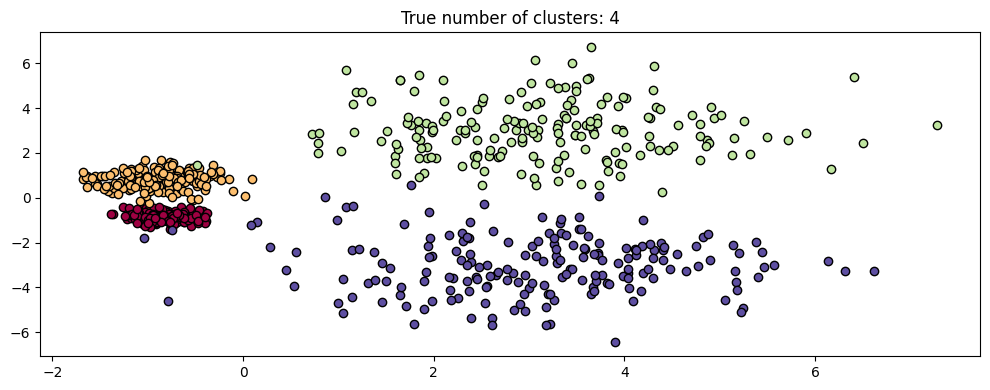

In [3]:
from sklearn.datasets import make_blobs

centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)

## Langkah 1 - Eksperimen Hyperparameter `min_cluster_size`

`min_cluster_size` adalah ukuran minimum sebuah grup titik agar dianggap cluster. Semakin besar nilainya, semakin sedikit cluster yang terbentuk (grup kecil bergabung/menjadi noise).

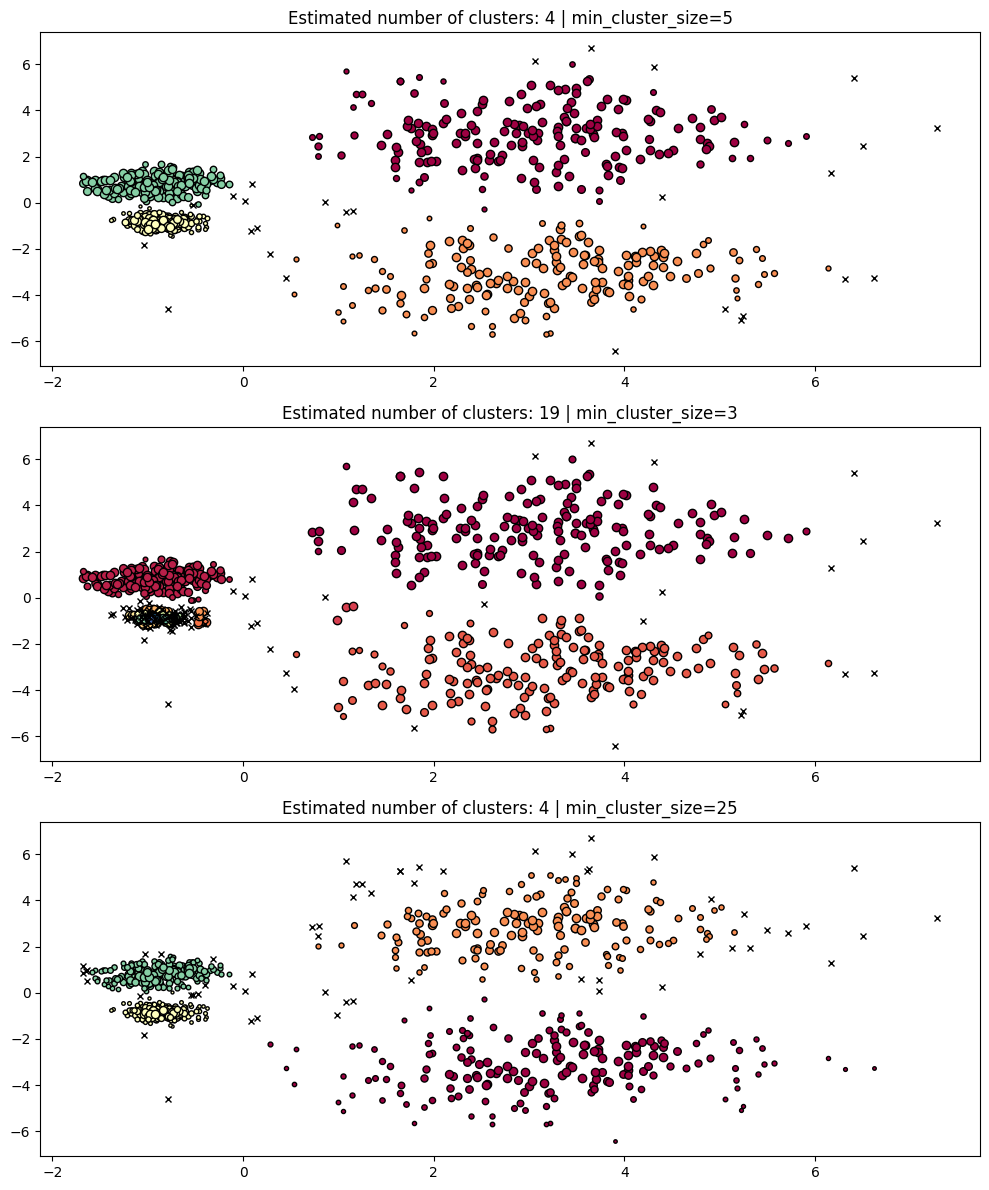

In [4]:
PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

Terlihat bahwa `min_cluster_size=3` dan `5` menghasilkan jumlah cluster yang lebih banyak karena grup kecil masih diizinkan menjadi cluster sendiri, sedangkan `min_cluster_size=25` menggabungkan grup-grup kecil sehingga jumlah cluster berkurang.

## Langkah 8 - Eksperimen Hyperparameter `min_samples`

`min_samples` mengendalikan tingkat *konservatisme* clustering: semakin besar nilainya, semakin konservatif (lebih banyak titik dinyatakan noise, cluster cenderung lebih murni namun dapat terpecah). Jika tidak disetel, default-nya sama dengan `min_cluster_size`.

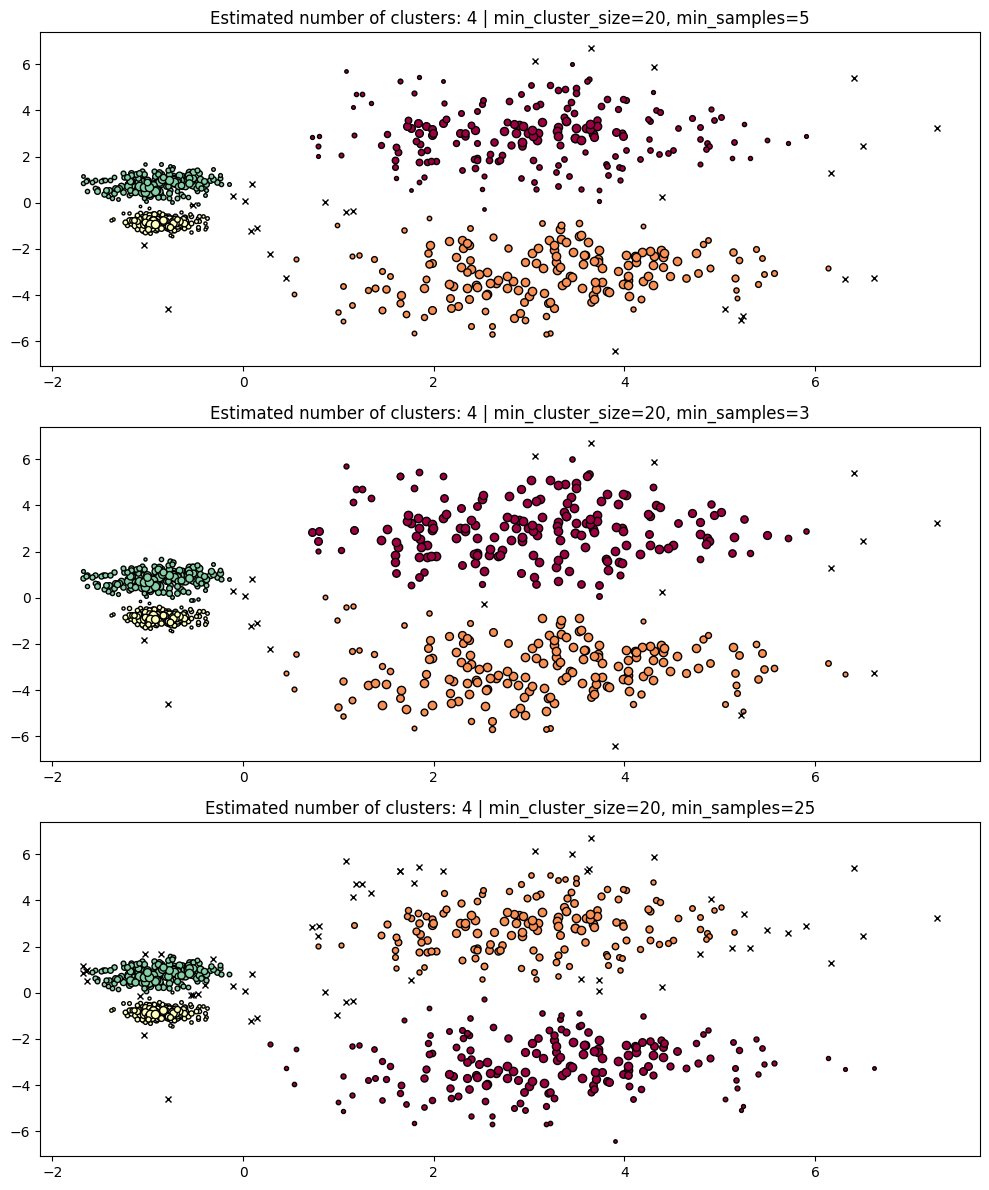

In [5]:
PARAM = (
    {"min_cluster_size": 20, "min_samples": 5},
    {"min_cluster_size": 20, "min_samples": 3},
    {"min_cluster_size": 20, "min_samples": 25},
)
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = hdbscan.HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

Dengan `min_samples` besar (25), lebih banyak titik yang dinyatakan noise (ditandai `x` hitam) dan titik yang tersisa memiliki keanggotaan (ukuran titik) lebih kecil, sedangkan `min_samples` kecil membuat cluster lebih padat dan penuh.

## Langkah 9 - DBSCAN Clustering dari Pohon HDBSCAN

Parameter `cut_distance` (via `dbscan_clustering`) memotong pohon hierarki HDBSCAN pada suatu kepadatan tertentu - perilakunya setara DBSCAN dengan `eps=cut_distance`, namun tanpa perlu melatih ulang model: cukup memotong pohon yang sama pada level berbeda.

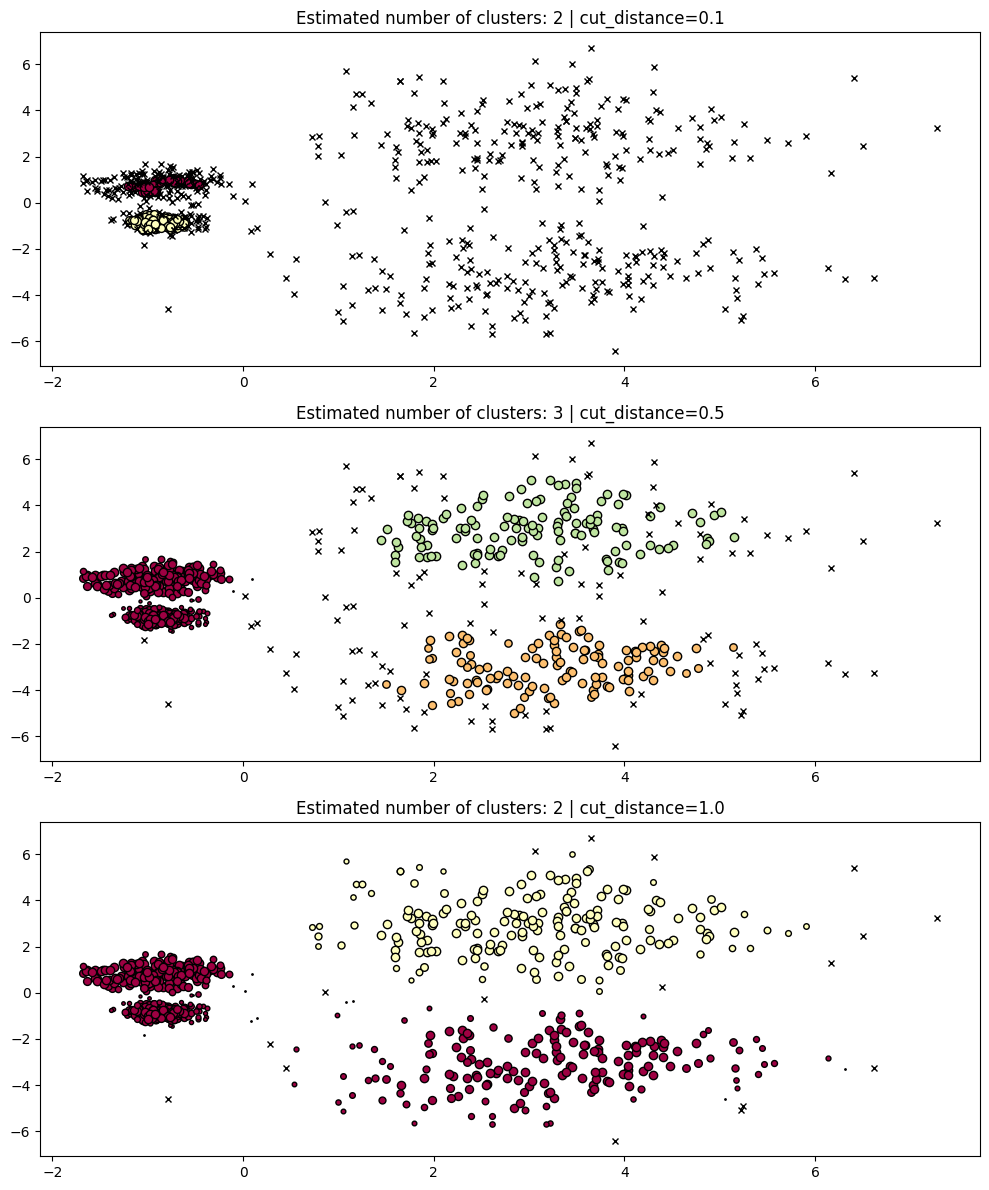

In [6]:
PARAM = (
    {"cut_distance": 0.1},
    {"cut_distance": 0.5},
    {"cut_distance": 1.0},
)
hdb = hdbscan.HDBSCAN().fit(X)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = hdb.dbscan_clustering(**param)
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

Semakin kecil `cut_distance`, semakin banyak cluster terbentuk (pohon dipotong pada level kepadatan tinggi); semakin besar, semakin banyak cluster yang bergabung. Dari satu model HDBSCAN, seluruh variasi "DBSCAN dengan eps berbeda" ini diperoleh tanpa komputasi ulang.

## Langkah 10 - Evaluasi dengan Silhouette Score

* Jika nilai Silhouette Score mendekati 1, clustering berhasil memisahkan data dengan baik.
* Nilai negatif menunjukkan data mungkin salah kelompok atau tidak tercluster dengan baik.

In [7]:
from sklearn.metrics import silhouette_score

# Menghitung Silhouette Score untuk hasil clustering HDBSCAN
sil_score = silhouette_score(X, hdb.labels_)
print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.5743816709862986


## Langkah 11 - Evaluasi dengan Davies-Bouldin Index

* **Davies-Bouldin Index** yang lebih rendah menunjukkan clustering lebih baik (cluster terpisah jelas dan homogen).
* Nilai yang lebih tinggi menunjukkan cluster saling tumpang tindih dan kurang terpisah jelas.

In [8]:
from sklearn.metrics import davies_bouldin_score

# Menghitung Davies-Bouldin Index untuk hasil clustering HDBSCAN
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.6436030674842066


## Langkah 12 - Visualisasi Hasil Evaluasi

Bandingkan DBI dan Silhouette Score dalam bentuk grafik:

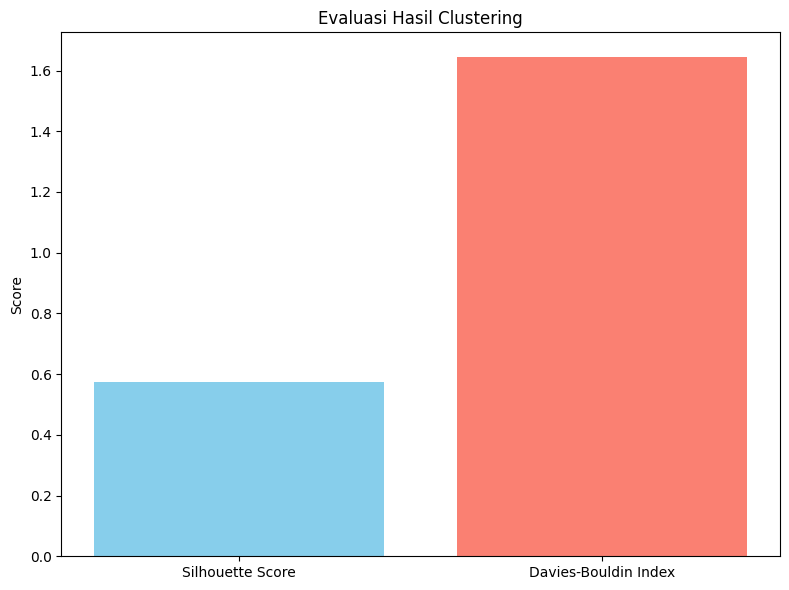

In [9]:
# Misalnya kita ingin membandingkan DBI dan Silhouette Score untuk beberapa eksperimen
scores = {
    "Silhouette Score": sil_score,
    "Davies-Bouldin Index": dbi_score
}

# Plot hasil evaluasi
fig, ax = plt.subplots(figsize=(8, 6))
ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
ax.set_title("Evaluasi Hasil Clustering")
ax.set_ylabel("Score")
plt.tight_layout()
plt.show()

**Kesimpulan Lab 3:** `min_cluster_size` mengendalikan ukuran minimum cluster (makin besar makin sedikit cluster), `min_samples` mengendalikan konservatisme (makin besar makin banyak noise), dan `cut_distance` memungkinkan perilaku seperti-DBSCAN pada berbagai level kepadatan dari satu pohon HDBSCAN. Evaluasi kuantitatif (Silhouette & DBI) melengkapi inspeksi visual untuk menilai kualitas clustering.